# ¿Qué tipo de modelo estima mejor el precio? (E7, comparación)

El primer modelo ([modelo_precio_e7.ipynb](modelo_precio_e7.ipynb)) usa *HistGradientBoosting* de
scikit-learn. Aquí se comparan **nueve enfoques** con exactamente los mismos datos, variables, partición y
métricas, de lo más simple a lo más potente:

| Familia | Modelo | Idea |
|---|---|---|
| Línea base | Mediana del m² por barrio | Lo que hace un agente a ojo (y, en versión fina, la alerta) |
| Lineal | Ridge | Suma ponderada de variables; rápido y explicable |
| Vecinos | kNN | Promedio de los inmuebles más parecidos y cercanos: "comparables" automáticos |
| Red neuronal | MLP (3 capas) | Aprende combinaciones no lineales; suele brillar con imágenes o texto, no tanto con tablas |
| Árboles | Random Forest | Promedio de muchos árboles independientes |
| *Boosting* | HistGradientBoosting (actual), XGBoost, LightGBM, CatBoost | Árboles que corrigen los errores de los anteriores; el estándar en datos tabulares |

**Reglas de juego:**

- Partición por **inmueble** (el mismo inmueble nunca en entrenamiento y prueba): 72% para ajustar, 8% de
  **validación** (parada temprana y elección de hiperparámetros) y 20% de **prueba**, que ningún modelo ve
  hasta el final.
- Mismas variables para todos (`src/modelo_precio.py`). Barrio, zona, comuna y ciudad van codificados por
  su precio medio, salvo en **CatBoost**, que los recibe tal cual porque tiene su propia codificación.
- Métrica principal: **error porcentual absoluto mediano** (MdAPE) del precio; también la proporción
  dentro de ±10% y ±20%.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE))
from src import modelo_precio as mp

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 140)
AZUL, GRIS, TINTA, TINTA_2 = "#2a78d6", "#a8a69f", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d4ce",
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5, "legend.frameon": False,
})
pct = lambda x: f"{x:.1%}".replace(".", ",")
mil = lambda x: f"{x:,.0f}".replace(",", ".")
FORMATO = {"MdAPE": pct, "±10%": pct, "±20%": pct, "avisos": mil, "segundos": "{:.0f}"}

## 1. Datos y partición

In [2]:
a, pasos = mp.limpiar(mp.cargar())
X, TE, AMENIDADES = mp.variables(a)
y, grupo = a["lpm2"].to_numpy(), mp.grupos(a)
d = a.assign(estrato=X["estrato"])                      # para la línea base (estrato limpio)
entrenamiento, prueba = mp.particion_grupos(grupo)
ajuste, validacion = mp.subparticion(entrenamiento, grupo)
print(f"{mil(len(a))} avisos de vivienda · {X.shape[1]} variables + {TE.shape[1]} de alta cardinalidad")
print(f"Ajuste: {mil(len(ajuste))} · validación: {mil(len(validacion))} · prueba: {mil(len(prueba))}")

122.387 avisos de vivienda · 57 variables + 4 de alta cardinalidad
Ajuste: 88.110 · validación: 9.746 · prueba: 24.531


## 2. Los candidatos

Cada función recibe las mismas piezas y devuelve la predicción (log del precio/m²) para la prueba. La
codificación de barrio, zona, comuna y ciudad se ajusta **solo** con el conjunto de ajuste.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

LOG = ["m2", "m2_construido", "m2_terreno", "admin_m2"]


def con_te(X, TE, y, ajuste, *otros):
    # X + columnas te_* (codificación por objetivo ajustada SOLO con `ajuste`)
    enc = mp.codificador()
    Xa = X.iloc[ajuste].copy()
    Xa[["te_" + c for c in TE.columns]] = enc.fit_transform(TE.iloc[ajuste], y[ajuste])
    salida = [Xa]
    for idx in otros:
        Xo = X.iloc[idx].copy()
        Xo[["te_" + c for c in TE.columns]] = enc.transform(TE.iloc[idx])
        salida.append(Xo)
    return salida


def matriz_densa(Xa):
    # Para modelos que necesitan números escalados (lineal, red neuronal): log de áreas, imputación con
    # indicador de faltante, escalado y one-hot de las categóricas
    num = [c for c in Xa.columns if c not in mp.CATEGORICAS]
    log = [c for c in LOG if c in num]
    resto = [c for c in num if c not in log]
    return ColumnTransformer([
        ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                              SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), log),
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), resto),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), mp.CATEGORICAS),
    ])

In [4]:
def mediana_barrio(X, TE, y, ajuste, validacion, prueba):
    return mp.linea_base(d.iloc[ajuste], d.iloc[prueba])


def ridge(X, TE, y, ajuste, validacion, prueba):
    Xa, Xp = con_te(X, TE, y, ajuste, prueba)
    return make_pipeline(matriz_densa(Xa), Ridge(alpha=3.0)).fit(Xa, y[ajuste]).predict(Xp)


def knn(X, TE, y, ajuste, validacion, prueba):
    # Los 15 más parecidos: dónde está (pesa más), cuánto mide, estrato, habitaciones, baños y tipo
    pesos = {"latitud": 4.0, "longitud": 4.0, "m2": 1.5, "estrato": 1.0, "habitaciones": 0.5, "banos": 0.5}
    pre = ColumnTransformer([
        *[(c, make_pipeline(FunctionTransformer(np.log1p if c == "m2" else None), SimpleImputer(strategy="median"),
                            StandardScaler(), FunctionTransformer(lambda v, w=w: v * w)), [c]) for c, w in pesos.items()],
        ("tipo", make_pipeline(OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                               FunctionTransformer(lambda v: v * 3.0)), ["tipo"]),
    ])
    cols = [*pesos, "tipo"]
    m = make_pipeline(pre, KNeighborsRegressor(n_neighbors=15, weights="distance", n_jobs=-1))
    return m.fit(X.iloc[ajuste][cols], y[ajuste]).predict(X.iloc[prueba][cols])


def red_neuronal(X, TE, y, ajuste, validacion, prueba):
    Xa, Xp = con_te(X, TE, y, ajuste, prueba)
    media = y[ajuste].mean()
    m = make_pipeline(matriz_densa(Xa), MLPRegressor(hidden_layer_sizes=(256, 128, 64), alpha=1e-4, batch_size=512,
                                                     learning_rate_init=1e-3, max_iter=200, early_stopping=True,
                                                     n_iter_no_change=10, random_state=mp.SEMILLA))
    return m.fit(Xa, y[ajuste] - media).predict(Xp) + media


def random_forest(X, TE, y, ajuste, validacion, prueba):
    Xa, Xp = con_te(X, TE, y, ajuste, prueba)
    for Z in (Xa, Xp):
        for c in mp.CATEGORICAS:
            Z[c] = Z[c].cat.codes
    m = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.4, n_jobs=-1, random_state=mp.SEMILLA)
    return m.fit(Xa, y[ajuste]).predict(Xp)

In [5]:
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool
from xgboost import XGBRegressor

XGB = dict(learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0)
LGBM = dict(learning_rate=0.03, num_leaves=127, min_child_samples=20, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.7, reg_lambda=1.0)


def hist_gb(X, TE, y, ajuste, validacion, prueba):
    Xa, Xv, Xp = con_te(X, TE, y, ajuste, validacion, prueba)
    m = HistGradientBoostingRegressor(max_iter=5000, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20,
                                      l2_regularization=1.0, categorical_features="from_dtype", early_stopping=True,
                                      n_iter_no_change=100, random_state=mp.SEMILLA)
    return m.fit(Xa, y[ajuste], X_val=Xv, y_val=y[validacion]).predict(Xp)


def xgboost(X, TE, y, ajuste, validacion, prueba, **params):
    Xa, Xv, Xp = con_te(X, TE, y, ajuste, validacion, prueba)
    m = XGBRegressor(n_estimators=10000, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
                     early_stopping_rounds=200, n_jobs=-1, random_state=mp.SEMILLA, **(XGB | params))
    m.fit(Xa, y[ajuste], eval_set=[(Xv, y[validacion])], verbose=False)
    return m.predict(Xp)


def lightgbm(X, TE, y, ajuste, validacion, prueba, **params):
    limpio = lambda Z: Z.rename(columns=lambda c: c.replace(":", "_").replace(" ", "_"))
    Xa, Xv, Xp = map(limpio, con_te(X, TE, y, ajuste, validacion, prueba))
    m = lgb.LGBMRegressor(n_estimators=10000, n_jobs=-1, random_state=mp.SEMILLA, verbose=-1, **(LGBM | params))
    m.fit(Xa, y[ajuste], eval_X=Xv, eval_y=y[validacion], callbacks=[lgb.early_stopping(200, verbose=False)])
    return m.predict(Xp)


def catboost(X, TE, y, ajuste, validacion, prueba):
    # Barrio, zona, comuna y ciudad TAL CUAL: CatBoost los codifica a su manera (estadísticas ordenadas)
    Z = X.copy()
    for c in mp.CATEGORICAS:
        Z[c] = Z[c].astype(str)
    Z[TE.columns] = TE
    cats = mp.CATEGORICAS + list(TE.columns)
    pool = lambda idx, con_y=True: Pool(Z.iloc[idx], y[idx] if con_y else None, cat_features=cats)
    m = CatBoostRegressor(iterations=10000, learning_rate=0.08, depth=8, l2_leaf_reg=3, od_type="Iter", od_wait=200,
                          thread_count=-1, random_seed=mp.SEMILLA, verbose=False,
                          allow_writing_files=False)
    m.fit(pool(ajuste), eval_set=pool(validacion), use_best_model=True)
    return m.predict(pool(prueba, False))


CANDIDATOS = {
    "Mediana del m² por barrio": mediana_barrio, "Lineal (Ridge)": ridge, "Vecinos más cercanos (kNN)": knn,
    "Red neuronal (MLP)": red_neuronal, "Random Forest": random_forest,
    "HistGradientBoosting (actual)": hist_gb, "XGBoost": xgboost, "LightGBM": lightgbm, "CatBoost": catboost,
}

## 3. Resultados en la prueba

Además de cada modelo solo, dos **ensambles** (promedio de las predicciones): XGBoost + LightGBM, y
XGBoost + LightGBM + CatBoost.

In [6]:
preds, segundos = {}, {}
for nombre, f in CANDIDATOS.items():
    t = time.time()
    preds[nombre] = f(X, TE, y, ajuste, validacion, prueba)
    segundos[nombre] = time.time() - t
preds["Ensamble XGBoost + LightGBM"] = np.mean([preds["XGBoost"], preds["LightGBM"]], axis=0)
preds["Ensamble XGBoost + LightGBM + CatBoost"] = np.mean([preds["XGBoost"], preds["LightGBM"], preds["CatBoost"]], axis=0)
segundos["Ensamble XGBoost + LightGBM"] = segundos["XGBoost"] + segundos["LightGBM"]
segundos["Ensamble XGBoost + LightGBM + CatBoost"] = segundos["XGBoost"] + segundos["LightGBM"] + segundos["CatBoost"]
errores = {k: mp.error(p, y[prueba]) for k, p in preds.items()}
res = pd.DataFrame({k: mp.metricas(e) | {"segundos": segundos[k]} for k, e in errores.items()}).T.sort_values("MdAPE")
res.style.format(FORMATO)

,MdAPE,±10%,±20%,avisos,segundos
Ensamble XGBoost + LightGBM + CatBoost,"11,4%","45,0%","72,7%",24.531,124
Ensamble XGBoost + LightGBM,"11,4%","44,6%","72,7%",24.531,28
XGBoost,"11,5%","44,5%","72,5%",24.531,16
LightGBM,"11,6%","44,4%","72,6%",24.531,12
CatBoost,"11,8%","43,8%","71,6%",24.531,96
HistGradientBoosting (actual),"11,9%","43,4%","71,4%",24.531,10
Random Forest,"12,2%","42,5%","69,7%",24.531,8
Red neuronal (MLP),"14,0%","37,5%","65,1%",24.531,9
Vecinos más cercanos (kNN),"14,2%","38,2%","62,9%",24.531,0
Lineal (Ridge),"15,5%","34,3%","60,9%",24.531,1


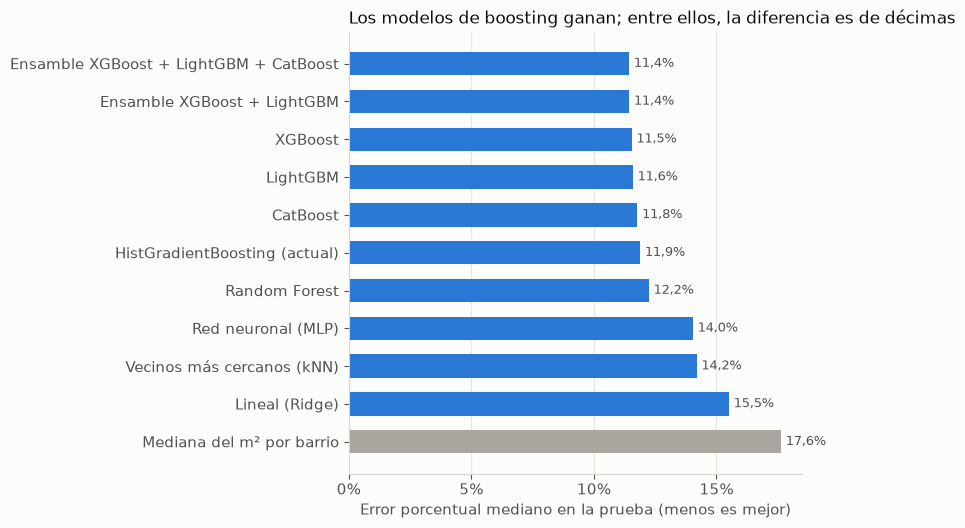

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 5.4))
filas = res.iloc[::-1]
colores = [GRIS if k == "Mediana del m² por barrio" else AZUL for k in filas.index]
ax.barh(filas.index, filas["MdAPE"], height=0.62, color=colores)
for i, v in enumerate(filas["MdAPE"]):
    ax.text(v + 0.002, i, pct(v), va="center", fontsize=9, color=TINTA_2)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Error porcentual mediano en la prueba (menos es mejor)")
ax.set_title("Los modelos de boosting ganan; entre ellos, la diferencia es de décimas", loc="left", fontsize=12, color=TINTA)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4. ¿Las diferencias son reales?

Con 24.500 avisos de prueba, una diferencia de décimas puede ser azar. *Bootstrap* pareado: se re-muestrean
los avisos de prueba 1.000 veces y en cada muestra se mide la diferencia de error mediano de cada modelo
frente al **actual** (HistGradientBoosting). Si el intervalo del 95% no toca el cero, la diferencia es real.

In [8]:
rng = np.random.default_rng(mp.SEMILLA)
B, n = 1000, len(prueba)
muestras = rng.integers(0, n, size=(B, n))
ref = np.median(errores["HistGradientBoosting (actual)"][muestras], axis=1)
filas = []
for k in res.index:
    if k == "HistGradientBoosting (actual)":
        continue
    dif = np.median(errores[k][muestras], axis=1) - ref
    lo, hi = np.percentile(dif, [2.5, 97.5])
    filas.append({"modelo": k, "diferencia": np.median(dif), "IC 95% desde": lo, "IC 95% hasta": hi,
                  "¿real?": "sí, mejor" if hi < 0 else ("sí, peor" if lo > 0 else "no se distingue")})
boot = pd.DataFrame(filas).set_index("modelo")
pp = lambda v: f"{v * 100:+.2f} pts".replace(".", ",")
boot.style.format({"diferencia": pp, "IC 95% desde": pp, "IC 95% hasta": pp})

,diferencia,IC 95% desde,IC 95% hasta,¿real?
modelo,,,,
Ensamble XGBoost + LightGBM + CatBoost,"-0,44 pts","-0,58 pts","-0,31 pts","sí, mejor"
Ensamble XGBoost + LightGBM,"-0,45 pts","-0,58 pts","-0,31 pts","sí, mejor"
XGBoost,"-0,34 pts","-0,48 pts","-0,20 pts","sí, mejor"
LightGBM,"-0,30 pts","-0,44 pts","-0,16 pts","sí, mejor"
CatBoost,"-0,11 pts","-0,26 pts","+0,04 pts",no se distingue
Random Forest,"+0,34 pts","+0,16 pts","+0,51 pts","sí, peor"
Red neuronal (MLP),"+2,16 pts","+1,94 pts","+2,40 pts","sí, peor"
Vecinos más cercanos (kNN),"+2,31 pts","+2,07 pts","+2,56 pts","sí, peor"
Lineal (Ridge),"+3,62 pts","+3,37 pts","+3,85 pts","sí, peor"


## 5. Afinamiento de XGBoost y LightGBM

Los resultados de arriba usan parámetros razonables, no afinados. Aquí, 10 combinaciones al azar de cada uno,
elegidas por su error en **validación** (la prueba no se usa para elegir). Solo la mejor de cada uno se
mide en la prueba.

In [9]:
ESPACIO = {
    "XGBoost": (xgboost, {"max_depth": [6, 8, 10], "min_child_weight": [1, 5, 10], "subsample": [0.7, 0.8, 1.0],
                          "colsample_bytree": [0.5, 0.7, 0.9], "learning_rate": [0.02, 0.03, 0.05],
                          "reg_lambda": [0.5, 1.0, 5.0]}),
    "LightGBM": (lightgbm, {"num_leaves": [31, 63, 127, 255], "min_child_samples": [10, 20, 50],
                            "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 0.9],
                            "learning_rate": [0.02, 0.03, 0.05], "reg_lambda": [0.0, 1.0, 5.0]}),
}
# Para elegir sin tocar la prueba: dentro del ajuste se separa un 10% como validación interna,
# y los candidatos se miden en `validacion`
aj_int, va_int = mp.subparticion(ajuste, grupo, semilla=2)
rng = np.random.default_rng(mp.SEMILLA)
afinados, filas = {}, []
for nombre, (f, espacio) in ESPACIO.items():
    mejor = (np.inf, None)
    for i in range(10):
        params = {k: v[rng.integers(len(v))] for k, v in espacio.items()}
        e_val = np.median(mp.error(f(X, TE, y, aj_int, va_int, validacion, **params), y[validacion]))
        mejor = min(mejor, (e_val, params), key=lambda t: t[0])
    afinados[nombre] = mejor[1]
    p = f(X, TE, y, ajuste, validacion, prueba, **mejor[1])
    errores[f"{nombre} afinado"] = mp.error(p, y[prueba])
    preds[f"{nombre} afinado"] = p
    filas.append({"modelo": nombre, "validación (mejor)": mejor[0],
                  "prueba sin afinar": res.loc[nombre, "MdAPE"], "prueba afinado": np.median(errores[f"{nombre} afinado"])})
display(pd.DataFrame(filas).set_index("modelo").style.format(pct))
for k, v in afinados.items():
    print(f"{k}: {v}")

,validación (mejor),prueba sin afinar,prueba afinado
modelo,,,
XGBoost,"11,2%","11,5%","11,4%"
LightGBM,"11,3%","11,6%","11,6%"


XGBoost: {'max_depth': 10, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.5, 'learning_rate': 0.02, 'reg_lambda': 0.5}
LightGBM: {'num_leaves': 127, 'min_child_samples': 20, 'subsample': 1.0, 'colsample_bytree': 0.7, 'learning_rate': 0.02, 'reg_lambda': 0.0}


## 6. Validación temporal: avisos nuevos de octubre

La prueba más cercana al uso real (la alerta califica avisos recién publicados): entrenar con lo publicado
antes del 1 de octubre y predecir lo publicado después. Solo los finalistas.

In [10]:
t_tr, t_te = mp.particion_temporal(a, grupo)
t_aj, t_va = mp.subparticion(t_tr, grupo)
FINALISTAS = {"HistGradientBoosting (actual)": hist_gb, "XGBoost": xgboost, "LightGBM": lightgbm, "CatBoost": catboost}
pt = {k: f(X, TE, y, t_aj, t_va, t_te) for k, f in FINALISTAS.items()}
pt["Ensamble XGBoost + LightGBM"] = np.mean([pt["XGBoost"], pt["LightGBM"]], axis=0)
pt["Ensamble XGBoost + LightGBM + CatBoost"] = np.mean([pt["XGBoost"], pt["LightGBM"], pt["CatBoost"]], axis=0)
pt["Mediana del m² por barrio"] = mp.linea_base(d.iloc[t_tr], d.iloc[t_te])
print(f"Entrenamiento: {mil(len(t_tr))} avisos publicados antes del 1-oct · prueba: {mil(len(t_te))} publicados después")
res_t = pd.DataFrame({k: mp.metricas(mp.error(p, y[t_te])) for k, p in pt.items()}).T.sort_values("MdAPE")
res_t.style.format(FORMATO)

Entrenamiento: 106.008 avisos publicados antes del 1-oct · prueba: 14.459 publicados después


,MdAPE,±10%,±20%,avisos
Ensamble XGBoost + LightGBM + CatBoost,"10,7%","47,5%","76,1%",14.459
Ensamble XGBoost + LightGBM,"10,8%","47,1%","75,9%",14.459
XGBoost,"10,8%","46,9%","75,7%",14.459
LightGBM,"10,8%","46,8%","75,6%",14.459
CatBoost,"11,0%","46,0%","75,1%",14.459
HistGradientBoosting (actual),"11,1%","45,6%","75,0%",14.459
Mediana del m² por barrio,"16,2%","33,0%","58,8%",14.459


## 7. Dónde gana cada uno: por tipo y por ciudad

In [11]:
cols = ["Mediana del m² por barrio", "HistGradientBoosting (actual)", "XGBoost", "LightGBM", "CatBoost",
        "Ensamble XGBoost + LightGBM + CatBoost"]
t = d.iloc[prueba][["tipo", "ciudad"]].assign(**{k: errores[k] for k in cols})
display(t.groupby("tipo")[cols].median().style.format(pct).highlight_min(axis=1, subset=cols[1:], props="font-weight:bold"))
top = t["ciudad"].value_counts().head(8).index
display(t[t["ciudad"].isin(top)].groupby("ciudad")[cols].median().loc[top]
        .style.format(pct).highlight_min(axis=1, subset=cols[1:], props="font-weight:bold"))

,Mediana del m² por barrio,HistGradientBoosting (actual),XGBoost,LightGBM,CatBoost,Ensamble XGBoost + LightGBM + CatBoost
tipo,,,,,,
Apartaestudio,"15,9%","9,9%","9,7%","9,8%","10,2%","9,6%"
Apartamento,"15,6%","10,3%","10,0%","10,0%","10,2%","9,9%"
Casa,"22,4%","16,5%","16,1%","16,0%","16,3%","15,8%"


,Mediana del m² por barrio,HistGradientBoosting (actual),XGBoost,LightGBM,CatBoost,Ensamble XGBoost + LightGBM + CatBoost
ciudad,,,,,,
Bogotá,"18,4%","10,8%","10,6%","10,6%","10,8%","10,5%"
Medellín,"19,2%","12,2%","12,1%","12,0%","12,0%","11,9%"
Cali,"18,7%","12,2%","11,8%","12,0%","12,2%","11,8%"
Barranquilla,"22,5%","13,1%","12,9%","12,6%","13,0%","12,5%"
Envigado,"12,9%","10,6%","10,2%","10,4%","10,8%","10,1%"
Cartagena,"22,1%","16,2%","15,2%","15,2%","16,0%","15,5%"
Manizales,"18,6%","12,1%","11,7%","12,0%","11,7%","11,4%"
Pereira,"17,1%","13,0%","12,5%","11,7%","13,1%","12,1%"


## 8. Conclusiones (estado del 26-oct-2026)

| Modelo | Error mediano (prueba) | Avisos nuevos de octubre | Frente al actual (IC 95%) | Entrenar |
|---|---|---|---|---|
| **Ensamble XGBoost + LightGBM** | **11,4%** | **10,8%** | −0,45 pts (−0,58 a −0,31) | ~30 s |
| XGBoost | 11,5% | 10,8% | −0,34 pts (−0,48 a −0,20) | ~16 s |
| LightGBM | 11,6% | 10,8% | −0,30 pts (−0,44 a −0,16) | ~13 s |
| CatBoost | 11,8% | 11,0% | no se distingue | ~95 s |
| HistGradientBoosting (actual) | 11,9% | 11,1% | — | ~11 s |
| Random Forest | 12,2% | — | +0,34 pts (peor) | ~8 s |
| Red neuronal, kNN, lineal | 14,0–15,5% | — | +2,2 a +3,6 pts (peor) | ≤ 9 s |
| Mediana del m² por barrio | 17,6% | 16,2% | +5,8 pts (peor) | — |

1. **El boosting gana con holgura.** La red neuronal, los vecinos más cercanos y el modelo lineal quedan
   2–4 puntos peor. Es lo esperable en datos tabulares: los árboles capturan solos las interacciones
   (estrato × zona × área) que un modelo lineal o una red pequeña no ven.
2. **XGBoost y LightGBM le ganan al actual**, pero por poco: ~0,3 puntos, una diferencia real (el intervalo
   no toca el cero). El ensamble de los dos gana ~0,45 puntos. Agregar CatBoost al ensamble no mejora nada y
   cuadruplica el tiempo.
3. **Afinar casi no mueve la aguja** (XGBoost 11,5% → 11,4%; LightGBM igual): los parámetros por defecto ya
   eran buenos. El límite está en los datos, no en las perillas.
4. **La mejora es pareja** en los tres tipos y en las ciudades grandes. El ensamble es el mejor en la
   mayoría; LightGBM solo, en Barranquilla, Cartagena y Pereira.
5. **En perspectiva:** pasar de la mediana del barrio (17,6%) al primer modelo (11,9%) ganó ~6 puntos;
   cambiar de algoritmo agrega ~0,5. **Lo que sigue tiene que venir de los datos:** el texto de la
   descripción, el área de las casas (E4), quitar duplicados entre anunciantes, servicios cercanos
   (`src/osm_pois.py`) y la mediana de los vecinos más parecidos como variable.

**Recomendación para producción:** el **ensamble XGBoost + LightGBM** (11,4%, ~30 s de entrenamiento), o
**LightGBM solo** si se prefiere una sola dependencia (11,6%, 13 s). Ambos son livianos
(`requirements-modelos.txt`). CatBoost y la red neuronal no compensan.